<b>Moving beyond building applications that simply respond to prompts and starting to build AI systems that can think, make decisions, use external tools, and execute tasks.

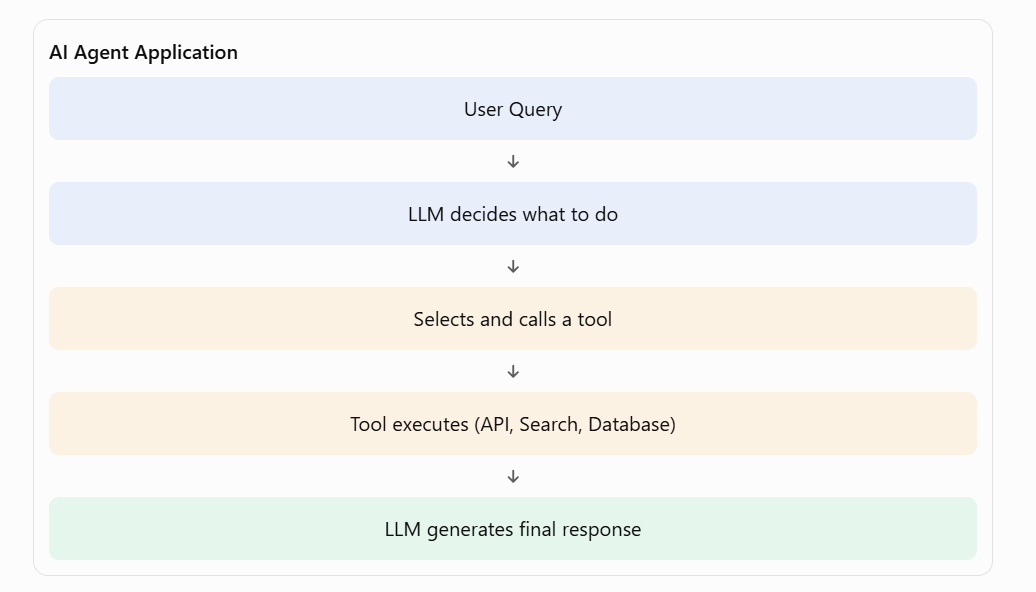

# Table of Contents

1. **Runnables**
2. Tools
3. Agents
4. Project

---

# 1. Runnables



<div style="background:linear-gradient(135deg,#EDE9FE,#DBEAFE); padding:18px; border-left:6px solid #7C3AED; border-radius:10px;">

<h2 style="color:#5B21B6; margin:0;">What are Runnables?</h2>

<strong>Runnables</strong> are the fundamental building blocks of LangChain that allow us to execute individual components and connect them together to create workflows.

</div>

## Why do we need Runnables?

In a typical LLM application, we may need to:

1. Pass input to a prompt.
2. Send the prompt to an LLM.
3. Process the LLM's response.
4. Return the final output.

Runnables provide a standardized way to execute and connect these components.

## Basic Workflow

User Input → Prompt → LLM → Output Parser → Final Output

## Important Runnable Methods

| Method | Purpose |
|---|---|
| `invoke()` | Executes a Runnable with a single input. |
| `batch()` | Executes a Runnable with multiple inputs. |
| `stream()` | Returns output progressively as it is generated. |
| `ainvoke()` | Asynchronously executes a Runnable. |
| `abatch()` | Asynchronously processes multiple inputs. |
| `astream()` | Asynchronously streams output. |

## Simple Example

```python
from langchain_core.runnables import RunnableLambda

def greet(name):
    return f"Hello, {name}!"

runnable = RunnableLambda(greet)

result = runnable.invoke("Rohit")

print(result)

## Actual Runnables

These are your components/runnables:

- LLM
- Prompt Template
- Output Parser
- Retriever
- Tools

> Basically: *They do the actual job.*

## Simple Sequence Runnables (RunnableSequence)

**Simple Sequence Runnables** allow us to connect multiple Runnables together in a specific order, where the output of one Runnable becomes the input of the next Runnable.

In simple words:

> It executes multiple components sequentially, one after another.

### Example Workflow

User Input → Prompt Template → LLM → Output Parser → Final Output

### How It Works

1. **Prompt Template:** Takes user input and creates a formatted prompt.
2. **LLM:** Receives the prompt and generates a response.
3. **Output Parser:** Processes the LLM response into the required format.
4. **Final Output:** Returns the processed result.

### Python Example

```python
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_groq import ChatGroq

prompt = ChatPromptTemplate.from_template(
    "Tell me a short joke about {topic}"
)

llm = ChatGroq(
    model="openai/gpt-oss-20b"
)

parser = StrOutputParser()

# Connecting Runnables using the pipe operator
chain = prompt | llm | parser

result = chain.invoke({"topic": "Python"})

print(result)

2. Parallel Runnables in LangChain allow you to execute multiple Runnables simultaneously using the same input and collect their outputs together.

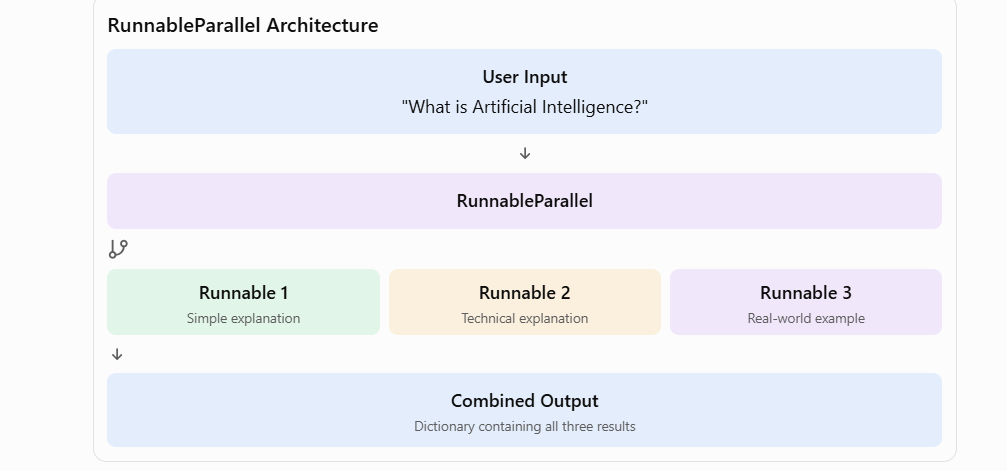

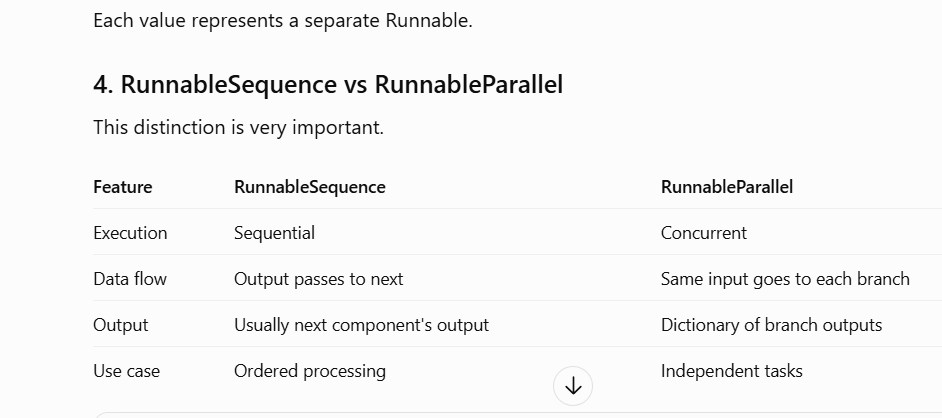

## Runnable Passthrough

<div style="background:#263D2B; padding:18px; border:2px solid #4ADE80; border-radius:8px; color:#F0FDF4;">

**Runnable Passthrough** is used when we want to keep the original input or some intermediate data while passing it through the pipeline.

Normally, in a sequence, each step replaces the previous output, so earlier data gets lost. But in many real-world scenarios, we need to carry multiple pieces of information together.

`RunnablePassthrough` allows us to forward the input as it is, without modifying it, so that it can be used along with other outputs in later steps.

**In simple terms**, it helps us preserve data while still continuing the flow of the pipeline.

</div>

# Difference Between 4 Types of Runnables

| Runnable | Main Purpose | When to Use |
|---|---|---|
| **RunnableSequence** | Executes multiple Runnables one after another. | When tasks need to run in a specific order. |
| **RunnableParallel** | Executes multiple Runnables simultaneously using the same input. | When you need multiple independent outputs at the same time. |
| **RunnableLambda** | Converts a normal Python function into a Runnable. | When you want to add custom Python logic to a chain. |
| **RunnablePassthrough** | Passes the original input forward without modifying it. | When you need to preserve the original input for later steps. |

---

## Quick Examples

1. **RunnableSequence:** Prompt → LLM → Output Parser.
2. **RunnableParallel:** Generate a summary and keywords simultaneously.
3. **RunnableLambda:** Apply a custom Python function to transform data.
4. **RunnablePassthrough:** Preserve the original question while generating another output.

## Remember the Difference

- **Sequence** → One after another.
- **Parallel** → At the same time.
- **Lambda** → Custom Python function.
- **Passthrough** → Keep the original input.

> **In short:** Sequence controls order, Parallel handles simultaneous tasks, Lambda adds custom logic, and Passthrough preserves data.

<div style="background:linear-gradient(135deg,#DCFCE7,#BBF7D0); padding:20px; border:3px solid #16A34A; border-left:10px solid #15803D; border-radius:12px; text-align:center;">

# ✅ RUNNABLES COMPLETED!

<p style="color:#166534; font-size:17px; font-weight:bold;">
Moving Towards the Next Topic
</p>

<div style="background:#FFFFFF; padding:12px; border:2px dashed #16A34A; border-radius:8px;">

<h2 style="color:#15803D; margin:0;">02. TOOLS</h2>

<p style="color:#166534; margin:6px 0 0;">
Next Step in AI Agents Learning
</p>

</div>
</div>

## Why Do We Need Tools in LLMs?

An LLM's core capabilities are:

- Think / Reason
- Generate an Answer

However, LLMs have limitations when performing certain real-world tasks.

### Limitations of LLMs

1. **No Real-Time Data** – LLMs cannot independently access live or up-to-date information.
2. **Not Reliable for Calculations** – LLMs can make mistakes when performing complex mathematical calculations.
3. **Cannot Call APIs** – LLMs cannot independently interact with external APIs or services.

### Why Tools?

**Tools** extend the capabilities of LLMs by allowing them to interact with external systems and perform tasks beyond text generation.

For example:
- Search the web for real-time information.
- Use a calculator for accurate calculations.
- Call APIs to retrieve external data.
- Execute Python code.

> **In simple terms:** Tools help LLMs move beyond just thinking and generating answers by allowing them to perform real-world actions.

<mark> What are tools ?

## 🛠️ What Are Tools?

<div style="background:linear-gradient(135deg,#142D25,#244B35); padding:22px; border:2px solid #4ADE80; border-left:8px solid #22C55E; border-radius:12px; color:#F0FDF4;">

<p style="font-size:17px; line-height:1.8; margin:0; color:#F0FDF4;">

**Tools** are simply <span style="color:#86EFAC; font-weight:800;">functions or external services</span> that an <span style="color:#93C5FD; font-weight:800;">LLM</span> can use to do <span style="color:#FDE68A; font-weight:800;">real-world tasks</span>.

On its own, an LLM can only generate text, but with tools it can:

- <span style="color:#67E8F9; font-weight:700;">Fetch live data</span>
- <span style="color:#C4B5FD; font-weight:700;">Perform accurate calculations</span>
- <span style="color:#F9A8D4; font-weight:700;">Access databases</span>
- <span style="color:#FDBA74; font-weight:700;">Execute actions</span>

</p>

<div style="background:#10251C; padding:13px; margin-top:15px; border:1px dashed #86EFAC; border-radius:8px;">

<p style="margin:0; font-size:16px; color:#FDE68A; font-weight:800;">💡 In Short:</p>

<p style="margin:7px 0 0; color:#F0FDF4; font-size:16px; line-height:1.6;">
Tools extend an LLM from just <em style="color:#93C5FD;">thinking</em> to actually <strong style="color:#86EFAC;">doing things.</strong>
</p>

</div>
</div>

## How Does an AI Agent Work?

<div style="background:linear-gradient(135deg,#172554,#312E81,#3B0764); padding:22px; border:2px solid #818CF8; border-left:8px solid #A78BFA; border-radius:12px; color:#F8FAFC;">

<p style="font-size:17px; line-height:1.8; margin:0;">

We use an <span style="color:#93C5FD; font-weight:800;">LLM as the brain</span>, <span style="color:#86EFAC; font-weight:800;">tools to perform tasks</span>, and <span style="color:#FDE68A; font-weight:800;">our code to define the logic</span>. Together, this creates an **AI Agent**.

</p>

<div style="background:#1E1B4B; padding:15px; border-radius:9px; margin-top:15px;">

<p style="margin:5px 0; color:#93C5FD;">**LLM** decides <em>what to do.</em></p>

<p style="margin:5px 0; color:#86EFAC;">**Tools** help <em>do the task.</em></p>

<p style="margin:5px 0; color:#FDE68A;">**Our Code** controls <em>how everything works together.</em></p>

</div>

<div style="background:linear-gradient(90deg,#064E3B,#164E63); padding:16px; margin-top:16px; border:2px solid #34D399; border-radius:9px; text-align:center;">

<h3 style="color:#A7F3D0; margin:0;">AGENT = BRAIN (LLM) + TOOLS + CONTROL LOGIC (OUR CODE)</h3>

</div>
</div>

# Categories of Tools

Tools are divided into **two main categories:**

<div style="display:flex; gap:12px; flex-wrap:wrap; margin:18px 0;">

<div style="flex:1; min-width:240px; background:linear-gradient(145deg,#172554,#1E40AF); padding:18px; border:2px solid #60A5FA; border-radius:12px;">

<h3 style="color:#BFDBFE; margin-top:0;">01. Built-in Tools</h3>

<p style="color:#F8FAFC; line-height:1.7;">
Built-in tools are tools that are already provided by a framework, so you don't have to create them from scratch.

They are ready to use and help the LLM perform common tasks like:

- Searching the internet
- Doing calculations
- Working with data

You just connect them to your LLM, and it can start using them easily.
</p>

</div>

<div style="flex:1; min-width:240px; background:linear-gradient(145deg,#3B0764,#701A75); padding:18px; border:2px solid #E879F9; border-radius:12px;">

<h3 style="color:#F5D0FE; margin-top:0;">02. Custom Tools</h3>

<p style="color:#FDF4FF; line-height:1.7;">
Custom tools are tools that **you create yourself** based on your needs.

They are usually simple functions written in code that help the LLM perform specific tasks, like:

- Accessing your database
- Processing your data
- Calling your own APIs

This allows you to give the LLM the **exact abilities that match your project.**
</p>

</div>
</div>

## Quick Difference

| Built-in Tools | Custom Tools |
|---|---|
| Already provided by a framework. | Created by you. |
| Ready to use. | Built according to your needs. |
| Used for common tasks. | Used for project-specific tasks. |

> **Remember:** Built-in Tools = Already Available  
> **Custom Tools = Create Yourself**

# Tool Binding

<div style="background:linear-gradient(135deg,#172554,#1E3A8A); padding:20px; border:2px solid #60A5FA; border-left:8px solid #38BDF8; border-radius:12px; color:#F8FAFC;">

**Tool Binding** means connecting our tools to the LLM so it can use them when needed.

We give our tools to the LLM, and now the LLM knows:

- <span style="color:#93C5FD;">What tools are available</span>
- <span style="color:#86EFAC;">What they do</span>
- <span style="color:#FDE68A;">When to use them</span>

</div>

# Tool Calling

<div style="background:linear-gradient(135deg,#3B0764,#581C87); padding:20px; border:2px solid #D8B4FE; border-left:8px solid #C084FC; border-radius:12px; color:#FAF5FF;">

In **Tool Binding**, we give tools to the LLM.

In **Tool Calling**, the LLM chooses to use them.

**Important:** The LLM does NOT execute the tool itself. It only suggests the tool call.

</div>

## Quick Difference

| Tool Binding | Tool Calling |
|---|---|
| Connects tools to the LLM. | LLM chooses which tool to use. |
| Makes tools available. | Requests a specific tool call. |
| Defines what tools the LLM can access. | LLM decides when a tool is needed. |

> **Remember:** Tool Binding = Making tools available  
> **Tool Calling = Choosing to use a tool**

# What is an AI Agent?

<div style="background:linear-gradient(135deg,#172554,#312E81); padding:20px; border:2px solid #818CF8; border-left:8px solid #A78BFA; border-radius:12px; color:#F8FAFC;">

An **AI Agent** is a system that uses an **LLM as its brain**, tools to perform tasks, and control logic (our code) to decide how everything works together.

Unlike a normal LLM that mainly generates text, an AI Agent can understand a task, decide which tools to use, perform actions, observe the results, and generate a final response.

</div>

## Core Components of an AI Agent

| Component | Role |
|---|---|
| **LLM (Brain)** | Decides what to do and reasons about the task. |
| **Tools** | Help perform tasks such as searching the web, calculations, and API calls. |
| **Control Logic (Code)** | Controls how the LLM and tools work together. |

<div style="background:#123B2B; padding:16px; border:2px solid #4ADE80; border-radius:10px; text-align:center;">

<h3 style="color:#BBF7D0; margin:0;">AI AGENT = LLM + TOOLS + CONTROL LOGIC</h3>

</div>

## How Does an AI Agent Work?

1. **User Input:** Receives a task from the user.
2. **Reasoning:** The LLM understands the task and decides what to do.
3. **Tool Selection:** Selects an appropriate tool if required.
4. **Tool Execution:** The tool performs the requested operation.
5. **Observation:** The LLM receives and processes the tool's result.
6. **Final Response:** Generates the answer or continues with another action.

## Example

**User:** Find the latest AI news.

- **LLM:** Understands the request.
- **Tool:** Uses a web search tool to fetch live news.
- **LLM:** Processes the search results.
- **Output:** Provides the latest AI news to the user.

## LLM vs AI Agent

| Normal LLM | AI Agent |
|---|---|
| Generates text. | Can perform multi-step tasks. |
| Responds to prompts. | Can decide when to use tools. |
| Does not independently execute external actions. | Can request external tool execution. |
| Usually answers directly. | Can observe results and take further actions. |

> **Key Takeaway:** An AI Agent combines the reasoning ability of an LLM, the capabilities of tools, and control logic to accomplish tasks.

<mark><b>Agents = LLMs + Tools + Decision Making

# Human-in-the-Loop (HITL) AI Agent

<div style="background:linear-gradient(135deg,#172554,#312E81); padding:20px; border:2px solid #818CF8; border-left:8px solid #A78BFA; border-radius:12px; color:#F8FAFC;">

**Human-in-the-Loop (HITL)** is an AI system design in which a human participates in the AI agent's decision-making or execution process by providing **approval, feedback, or corrections** before certain actions are performed.

</div>

## In Simple Words

<div style="background:linear-gradient(135deg,#14532D,#166534); padding:17px; border:2px solid #4ADE80; border-radius:10px; color:#F0FDF4;">

An AI agent makes decisions, but a **human supervises or approves important actions** before the agent executes them.

</div>

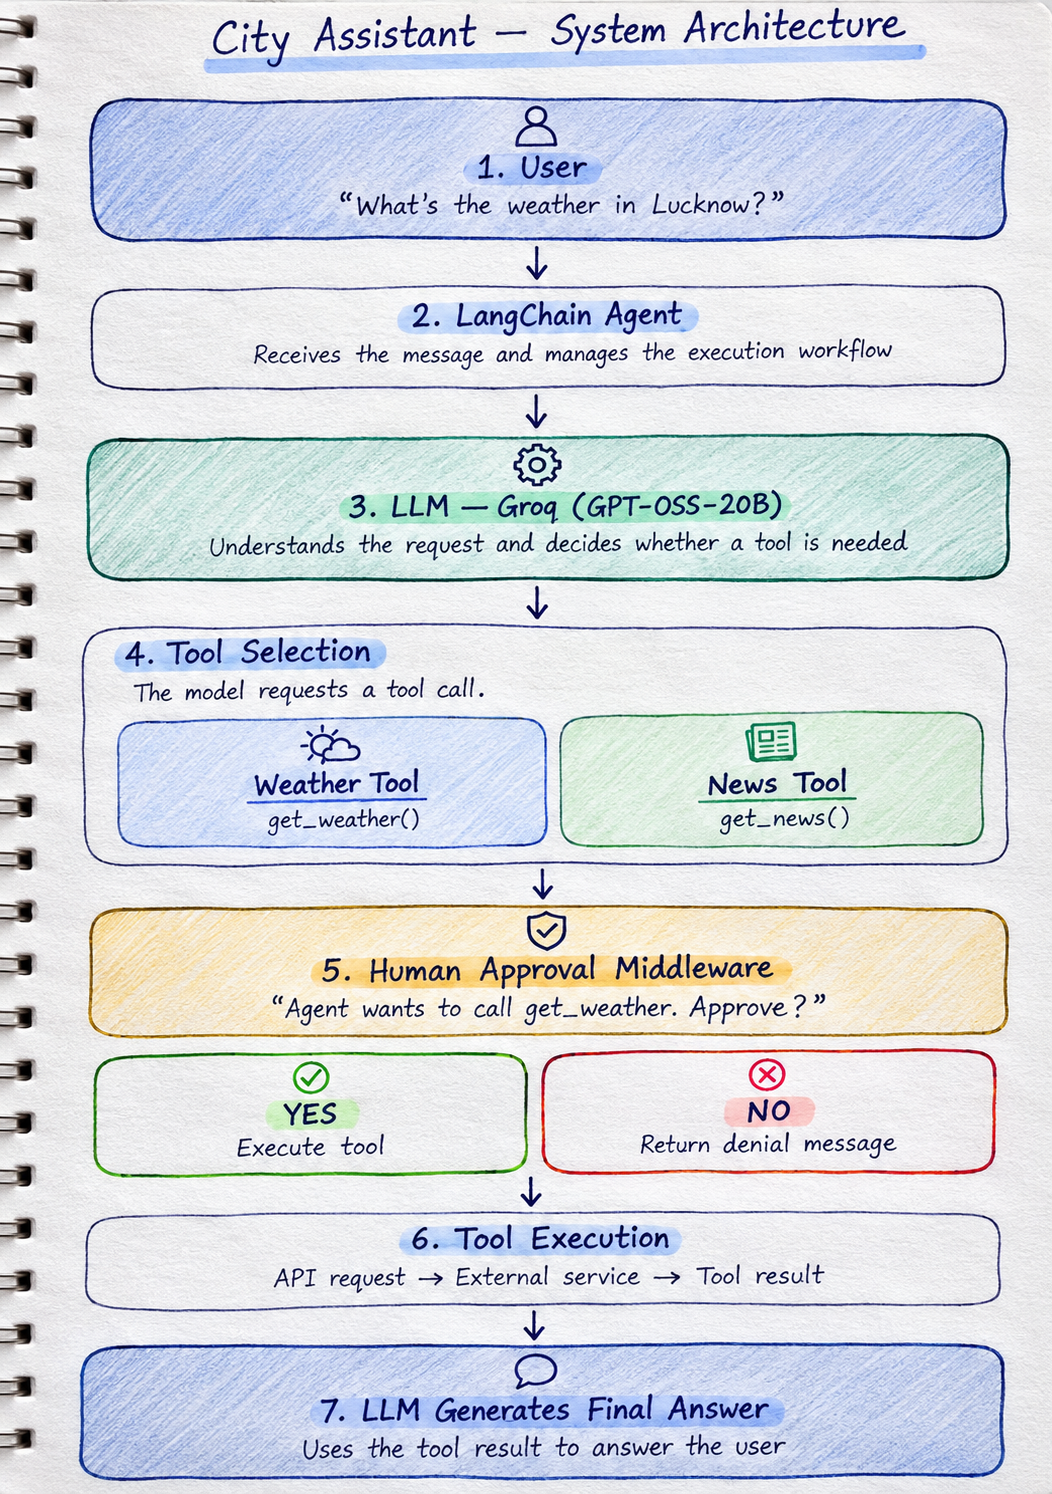